## 08A Evaluation: Classification View

#### Purpose
- Score the frozen claim and lapse models once on the evaluation split, and save the predictions for notebook 08b.
- Evaluate them as **classifiers**, the standard machine-learning view from our course: confusion matrices with accuracy, precision, recall and F1, and ROC curves with their AUC.
- Benchmark every model against the two naive rules.

The probability checks (log loss, Brier score, calibration) and the business analyses (segments, stability, cohort survival, monitoring) are in **08b**.

#### Rules for this notebook
1. **The holdout is opened once.** Every choice (features, settings, which model) was made on the training years and on out-of-time 1 (test, 2021–2022). Here the models are **frozen**: no refitting, no new settings.
2. **Dry run first.** `EVAL_SPLIT` (Step 0.2) stays `"test"` until 07a and 07b are final; we set it to `"valid"` once, for the final run.
3. **Every model the same way.** Every model saved in `data/processed/models/` is scored with the same code, so the 07a/07b models join automatically.

#### Steps:
0. Settings and the holdout switch
1. The models and the evaluation data
2. Score the evaluation split; set the cut-offs on the training split
3. **Claim model:** benchmark table, confusion matrices, ROC curve, train vs test vs validation, saved results of models scored elsewhere
4. **Lapse model:** benchmark table, confusion matrices, ROC curve, train vs test vs validation, saved results of models scored elsewhere
5. Conclusions and save

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-17

### Section 0. Load the libraries and working directory
Use the same setup cell as notebook 02 (repo root, data folders, reports folder), so the notebook runs on every teammate's machine. The shared evaluation code is in `src/evaluation.py`, so the claim and lapse sections run exactly the same steps.

#### 0.1 Imports and paths

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs
from src.db import connect
from src import evaluation as ev
pd.options.display.float_format = "{:,.4g}".format     # 4 significant digits, so small rates stay readable

ensure_dirs()

#### 0.2 Settings and the holdout switch
`EVAL_SPLIT` decides which out-of-time period is evaluated:

| `EVAL_SPLIT` | Years evaluated | When |
|---|---|---|
| `"test"` | OOT1, 2021–2022 | Dry run: as often as we like, while 07a/07b are being built |
| `"valid"` | OOT2, 2023 – Aug 2024 | **Once**, after 07a and 07b are final |

**08a and 08b must use the same value**: 08a scores the split and saves the predictions, 08b reads them (and stops if they were made for another split). In the dry run, nothing after 2022 is read. Every saved file carries the name of the split (`eval_test_…` or `eval_valid_…`), so the dry run never overwrites the final results.

The models of each target are read from `data/processed/models/<claim|lapse>_*.joblib` (written by 06a/06b and 07a/07b). Each file must be **one `joblib` dict** with `preprocess` (the fitted preprocessing), `model` (with `predict_proba`) and `features`; a `calibrator` is applied to the model's probability when the 07 notebook used it, and a model saved with `raw_input` (07b XGBoost, whose preprocessing applies the clean-up rules itself) gets the raw rows. The **primary model**, shown in the charts, is the advanced model with the lowest test log loss in its run record, unless `PRIMARY_CHOICE` names one. The two **naive benchmarks** are rebuilt from the training split exactly as in 06a/06b: the **base rate** (the training rate for everyone) and the **segment rate** (the training rate of each segment: claims, zone group × earlier claim; lapse, new business × mandatory purchase).

In [2]:
# Step 0.2 Settings, the model registry and the naive benchmarks

EVAL_SPLIT = "valid"        # change to "valid" ONCE, in 08a and 08b, after notebooks 07a and 07b are final
assert EVAL_SPLIT in ("test", "valid")
EVAL_NAME = ev.EVAL_NAMES[EVAL_SPLIT]
LAST_YEAR = 2022 if EVAL_SPLIT == "test" else 2024     # later years stay closed in the dry run
OUT = f"eval_{EVAL_SPLIT}"                             # prefix of every saved file
SEED = 42
MODEL_DIR, PRED_DIR = PROCESSED / "models", PROCESSED / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)
KINDS = pd.read_csv(DOCS / "feature_plan.csv").set_index("feature")["kind"].to_dict()   # num / cat / flag per feature

con = connect(db_path=None, memory_limit="6GB")
con.execute(f"CREATE OR REPLACE VIEW feats AS SELECT * FROM read_parquet('{PROCESSED / 'features.parquet'}')")

# The primary model of each target (shown in the charts): None = the advanced model with the lowest test log loss
# in its run record, otherwise the baseline. Set a model name, e.g. {"lapse": "lapse_rf"}, to choose it yourself.
PRIMARY_CHOICE = {"claim": None, "lapse": None}

# The models of each target, the primary model, and the two naive benchmarks rebuilt from the training split
registry, PRIMARY, base_rate, COLS = {}, {}, {}, {}
for kind in ev.TARGETS:
    registry[kind] = ev.load_registry(kind, MODEL_DIR, REPORTS)
    PRIMARY[kind] = ev.primary_model(registry[kind], PRIMARY_CHOICE.get(kind))
    base_rate[kind] = ev.build_benchmarks(con, kind)
    COLS[kind] = ev.model_columns(registry[kind])      # probability column of each model, in table order

N_CHUNKS = 8               # the evaluation split is scored in 8 chunks of about 0.9M rows
TRAIN_CHUNKS = 28         # every training row is scored in 28 chunks of about 1M rows (Step 2.2)
print(f"evaluating on {EVAL_NAME}; outputs saved as {OUT}_*")
display(pd.concat([ev.registry_table(k, registry[k], PRIMARY[k]) for k in ev.TARGETS], ignore_index=True))
pd.DataFrame({"base_rate_train": base_rate}).style.format("{:.4%}")

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


evaluating on OOT2 (validation, 2023 - Aug 2024); outputs saved as eval_valid_*


,target,model,primary,type,features,trained_on,settings,epochs,saved_at
0,claim,claim_baseline_logreg,False,SGDClassifier,52,"train (2014-2020), every row, in chunks","alpha=1e-06, eta0=0.001",1,2026-11-17T16:43:20
1,claim,claim_lgbm,False,LightGBM Booster,52,train (2014-2020): every claim + 10% of the ot...,,NaN,2026-11-17T21:34:35
2,claim,claim_rf,False,RandomForestClassifier,52,train (2014-2020): every claim + 10% of the ot...,,NaN,2026-11-17T20:31:58
3,claim,claim_xgb,True,XGBoost Booster,52,train (2014-2020): every claim + 10% of the ot...,,NaN,2026-11-17T22:20:59
4,lapse,lapse_baseline_logreg,False,SGDClassifier,68,"train (2014-2020), every row, in chunks","alpha=1e-06, eta0=0.01",1,2026-11-17T17:22:10
5,lapse,lapse_rf,True,RandomForestClassifier,68,"train (2014-2020), all 26,758,825 rows, read i...",,NaN,2026-11-17T20:38:22
6,lapse,lapse_xgb,False,XGBClassifier,68,"all 26,758,825 training rows, 06b's 28 chunks ...",,NaN,None


,base_rate_train
claim,1.3013%
lapse,13.8393%


### Section 1. The models and the evaluation data

#### 1.1 The time split
The models learned on the **development** years (2014–2020), their settings were chosen with **in-time** rolling folds inside those years, and they were compared on **out-of-time 1** (2021–2022). The final result is on **out-of-time 2** (2023 to August 2024), which no step has used.

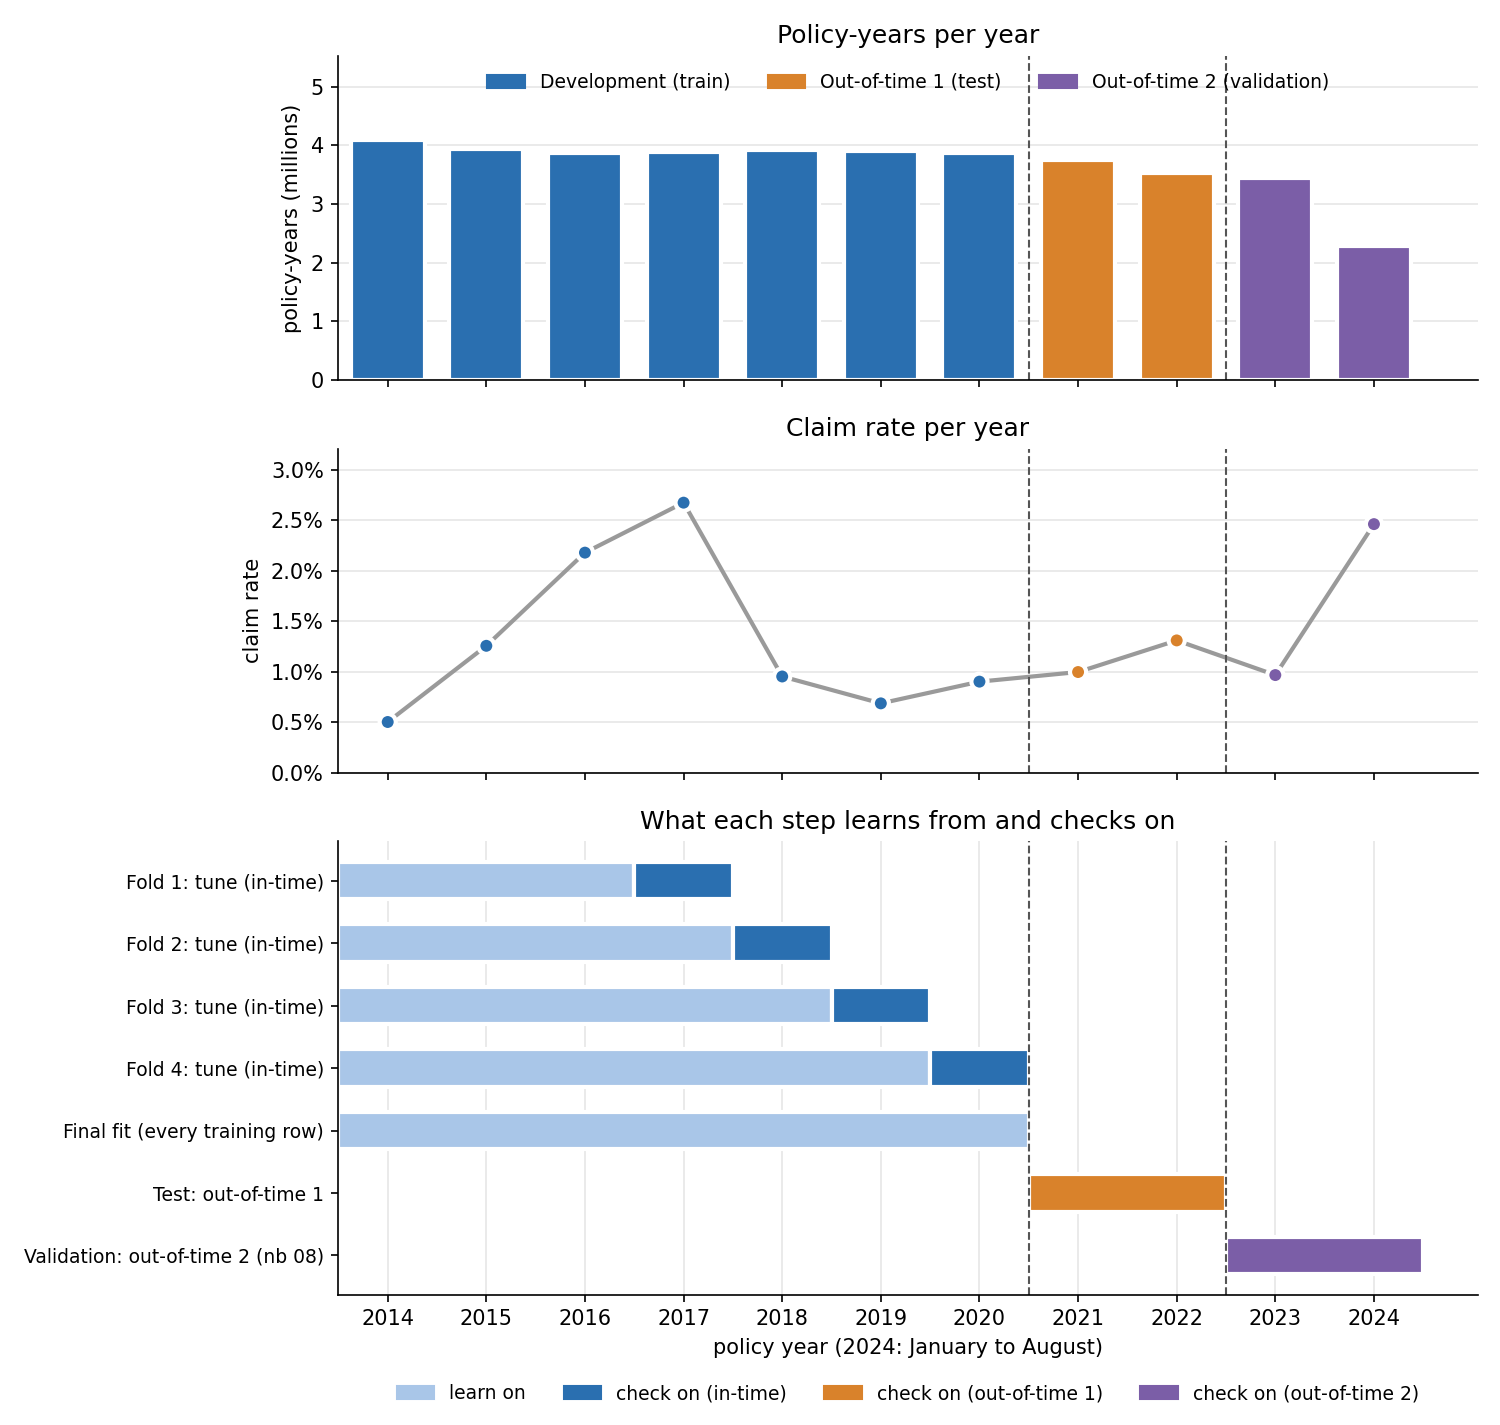

In [3]:
# Step 1.1 The time split (the figure saved by notebook 06a)
fig_path = REPORTS / "fig_claim_time_split.png"
display(Image(filename=str(fig_path), width=800)) if fig_path.exists() else print("run Step 1.2 of notebook 06a to draw the time split")

#### 1.2 Are the outcomes fully observed?
A policy-year can only be judged if its whole term has been observed. We check that the last term in the evaluation split ends before the claims data do, and how far the storm tracks (used for the storm segment in 08b) reach.

In [4]:
# Step 1.2 Terms in the evaluation split, and how far each source reaches
terms = con.sql(f"""
    SELECT period_year, COUNT(*) AS policy_years, MIN(period_start) AS first_start, MAX(period_start) AS last_start,
           MAX(period_end) AS last_end, AVG(exposure) AS mean_exposure
    FROM feats WHERE split = '{EVAL_SPLIT}' AND in_pop_claim GROUP BY ALL ORDER BY period_year""").df()
display(terms)
claims_end = con.execute(f"SELECT MAX(loss_date) FROM read_parquet('{PROCESSED / 'claim_links' / '*.parquet'}')").fetchall()[0][0]
storm_end = con.execute(f"SELECT MAX(wind_date) FROM read_parquet('{PROCESSED / 'storm_wind.parquet'}')").fetchall()[0][0]
last_end = terms["last_end"].max()
print(f"last term ends {last_end}; claims data reach {claims_end}; storm tracks reach {storm_end}")
print("claim outcomes fully observed:", pd.Timestamp(claims_end) >= pd.Timestamp(last_end))
if pd.Timestamp(storm_end) < pd.Timestamp(last_end):
    print("note: storms after the end of the IBTrACS file are missing from the storm segment in 08b")

,period_year,policy_years,first_start,last_start,last_end,mean_exposure
0,2023,3443343,2023-01-01,2023-12-31,2024-12-31,0.9913
1,2024,2281447,2024-01-01,2024-08-31,2025-08-31,0.9888


last term ends 2025-08-31 00:00:00; claims data reach 2026-09-07; storm tracks reach 2024-11-17
claim outcomes fully observed: True
note: storms after the end of the IBTrACS file are missing from the storm segment in 08b


### Section 2. Score the evaluation split

#### 2.1 Score every row with every model
We read the evaluation split chunk by chunk (as in 06a/06b), apply the same fixed clean-up rules, and score each row with every model and both benchmarks. For each row we also keep the columns 08b uses to cut the results (state, flood zone, new business, mandatory purchase, policy history, and the strongest storm wind at the property **during** the term, an outcome-period measure used only to describe the results, never as a feature).

The predictions are **saved right away** (`data/processed/predictions/eval_<split>_<target>_predictions.parquet`), so 08b reads them instead of scoring the holdout a second time.

In [5]:
# Step 2.1 Score the evaluation split with every model, chunk by chunk, and save the predictions for 08b
ev.build_storm_term(con, EVAL_SPLIT, PROCESSED / "storm_wind.parquet")
t0 = time.time()
pred = {}
for kind in ev.TARGETS:
    pred[kind] = ev.score_split(con, kind, registry[kind], base_rate[kind], KINDS, EVAL_SPLIT, n_chunks=N_CHUNKS, seed=SEED)
    keep = ["period_id", "policy_key", "period_year", "period_start", "state", "zone_group", "new_business",
            "mandatory_purchase", "storm_in_term", "history", "y", *COLS[kind].values()]
    pred[kind][keep].to_parquet(PRED_DIR / f"{OUT}_{kind}_predictions.parquet", index=False)
    print(f"{kind}: scored {len(pred[kind]):,} rows of {EVAL_NAME}, actual rate {pred[kind]['y'].mean():.3%} "
          f"({(time.time() - t0) / 60:.1f} min so far)")
(REPORTS / f"{OUT}_08a_run.json").write_text(json.dumps(
    {"eval_split": EVAL_SPLIT, "evaluated": EVAL_NAME, "scored_at": pd.Timestamp.now().isoformat(timespec="seconds"),
     "primary": PRIMARY, "models": {k: list(v) for k, v in registry.items()}, "base_rate_train": base_rate}, indent=2))
print(f"saved the predictions and the run record ({OUT}_08a_run.json) for 08b")

claim: scored 5,724,790 rows of OOT2 (validation, 2023 - Aug 2024), actual rate 1.564% (3.0 min so far)


/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

lapse: scored 5,621,274 rows of OOT2 (validation, 2023 - Aug 2024), actual rate 10.297% (4.5 min so far)
saved the predictions and the run record (eval_valid_08a_run.json) for 08b


#### 2.2 Cut-offs, set on the training split
A model gives a probability; a confusion matrix needs a yes/no decision, so we need a **cut-off** *c*: flag the policy-year if $p_i \ge c$. Every cut-off is set on the model's predictions for **every row of the training split** (27.5M claim and 26.8M lapse policy-years, scored chunk by chunk), so the evaluation outcomes are never used to choose it. The same training predictions give the train column of Steps 3.5 and 4.5.

| Rule | Cut-off | Why |
|---|---|---|
| Riskiest *q* of policy-years | the $(1-q)$ quantile of the training predictions, $c_q = \text{quantile}_{1-q}\big(\{p_j\}_{j \in \text{train}}\big)$ | claims: *q* = 5%, 10%, 20%; lapse: *q* = 10%, 20%, 30% (a fixed size of the group an insurer can act on) |
| F1-optimal | the cut-off with the highest F1 on the training split | the usual way to choose a single threshold from the data |
| Default | 0.5 | for comparison: with rare events it flags almost nobody |

Because the cut-off comes from training, the share flagged in the evaluation years can differ from *q*; a large difference means the scores have moved since training. The **segment rule** has only a handful of distinct values (8 segments), so two rules can share the same cut-off and flag far more or fewer than *q*: for claims, the 10% and 20% rules both flag about half the book.

In [6]:
# Step 2.2 The cut-off rules of every model, from every row of the training split
# (only the outcome and the probabilities are kept, about 0.5 GB per target)
RULES, TRAIN_SCORED = {}, {}
t0 = time.time()
for kind in ev.TARGETS:
    TRAIN_SCORED[kind] = ev.score_split_light(con, kind, registry[kind], base_rate[kind], KINDS, "train",
                                              n_chunks=TRAIN_CHUNKS, seed=SEED)
    RULES[kind] = {name: ev.cutoff_rules(kind, TRAIN_SCORED[kind], col) for name, col in COLS[kind].items() if name != "base rate"}
    print(f"{kind}: scored {len(TRAIN_SCORED[kind]):,} training rows ({(time.time() - t0) / 60:.1f} min so far)")
pd.DataFrame([{"target": k, "model": m, "rule": r, "cut_off": c} for k in RULES for m in RULES[k] for r, c in RULES[k][m].items()]
             ).pivot_table(index=["target", "model"], columns="rule", values="cut_off").round(4)

claim: scored 27,496,820 training rows (14.9 min so far)


/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/src/modeling.py:194: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  values = values.fillna(pd.Series(random_values[f], index=clean.index))
/Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/sr

lapse: scored 26,758,825 training rows (23.3 min so far)


rule                          F1-optimal in train  p >= 0.5 (default)  \
target model                                                            
claim  claim_baseline_logreg               0.0334                 0.5   
       claim_lgbm                          0.2203                 0.5   
       claim_rf                            0.1178                 0.5   
       claim_xgb                           0.1711                 0.5   
       segment rate                        0.0297                 0.5   
lapse  lapse_baseline_logreg               0.1599                 0.5   
       lapse_rf                            0.1892                 0.5   
       lapse_xgb                           0.1779                 0.5   
       segment rate                        0.1598                 0.5   

rule                          riskiest 10% in train  riskiest 20% in train  \
target model                                                                 
claim  claim_baseline_logreg                 0.0249                 0.0179   
       claim_lgbm                            0.0206                 0.0098   
       claim_rf                              0.0258                 0.0147   
       claim_xgb                             0.0219                 0.0113   
       segment rate                           0.014                  0.014   
lapse  lapse_baseline_logreg                 0.2511                 0.1935   
       lapse_rf                              0.2601                 0.2019   
       lapse_xgb                             0.2529                 0.1959   
       segment rate                          0.2351                 0.1598   

rule                          riskiest 30% in train  riskiest 5% in train  
target model                                                               
claim  claim_baseline_logreg                    NaN                0.0335  
       claim_lgbm                               NaN                0.0453  
       claim_rf                                 NaN                0.0456  
       claim_xgb                                NaN                0.0441  
       segment rate                             NaN                0.0297  
lapse  lapse_baseline_logreg                 0.1591                   NaN  
       lapse_rf                               0.167                   NaN  
       lapse_xgb                             0.1607                   NaN  
       segment rate                          0.1189                   NaN

### Section 3. Claim model

#### 3.1 Benchmark table
For every model and both benchmarks, overall and for each year:
- **ROC-AUC**: how well the model ranks policy-years (Step 3.4); 0.5 = no better than chance.
- **At the main rule** (flag the riskiest 10% of policy-years, cut-off from training): the share flagged, accuracy, precision, recall, F1 and lift.

$$\text{Accuracy} = \frac{TP+TN}{n} \qquad \text{Precision} = \frac{TP}{TP+FP} \qquad \text{Recall} = \frac{TP}{TP+FN} \qquad F_1 = \frac{2\cdot\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} \qquad \text{Lift} = \frac{\text{Precision}}{\text{actual rate}}$$

The base rate gives everyone the same probability, so it cannot flag a subgroup: it only has an ROC-AUC (0.5).

In [7]:
# Step 3.1 Claim: ROC-AUC and the measures at the main rule, for every model, overall and per year
p = pred["claim"]
scopes = [(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]]
bench_claim, main_rule = ev.benchmark_classification("claim", scopes, COLS["claim"], RULES["claim"])
print(f"main rule: {main_rule}")
bench_claim.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "roc_auc": "{:.4f}",
                           "flagged_share": "{:.1%}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}",
                           "f1": "{:.3f}", "lift": "{:.2f}"}, na_rep="-")

main rule: riskiest 10% in train


,scope,model,rows,events,actual_rate,roc_auc,flagged_share,accuracy,precision,recall,f1,lift
0,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,724,790","89,516",1.564%,0.5000,-,-,-,-,-,-
1,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,724,790","89,516",1.564%,0.6845,9.9%,0.892,3.52%,22.3%,0.061,2.25
2,"OOT2 (validation, 2023 - Aug 2024)",claim_baseline_logreg,"5,724,790","89,516",1.564%,0.6498,14.8%,0.846,2.99%,28.3%,0.054,1.91
3,"OOT2 (validation, 2023 - Aug 2024)",claim_lgbm,"5,724,790","89,516",1.564%,0.7093,14.3%,0.852,3.88%,35.5%,0.070,2.48
4,"OOT2 (validation, 2023 - Aug 2024)",claim_rf,"5,724,790","89,516",1.564%,0.7355,16.3%,0.834,3.91%,40.9%,0.071,2.50
5,"OOT2 (validation, 2023 - Aug 2024)",claim_xgb,"5,724,790","89,516",1.564%,0.6691,9.6%,0.897,4.03%,24.6%,0.069,2.58
6,2023,base rate,"3,443,343","33,302",0.967%,0.5000,-,-,-,-,-,-
7,2023,segment rate,"3,443,343","33,302",0.967%,0.6795,9.8%,0.897,2.40%,24.4%,0.044,2.48
8,2023,claim_baseline_logreg,"3,443,343","33,302",0.967%,0.6389,13.7%,0.859,1.90%,26.9%,0.036,1.97
9,2023,claim_lgbm,"3,443,343","33,302",0.967%,0.6954,13.9%,0.858,2.39%,34.2%,0.045,2.47


#### 3.2 Out-of-time 1 next to out-of-time 2 (or: dry-run check)
- **Final run (`"valid"`):** the same measures on OOT1, from the test predictions saved by 06a/07a, with the same cut-offs. A model whose results fall sharply from OOT1 to OOT2 was tuned too closely to 2021–2022.
- **Dry run (`"test"`):** the evaluation split *is* OOT1, so the ROC-AUC here must equal the one from the predictions saved by 06a. A difference means a model was loaded or prepared differently from how it was trained.

In [8]:
# Step 3.2 Claim: OOT1 from the saved test predictions
saved = ev.load_saved_test(PRED_DIR, registry["claim"])
if saved is None:
    print("no saved test predictions")
else:
    cols_saved = {n: c for n, c in COLS["claim"].items() if c in saved}
    oot1, _ = ev.benchmark_classification("claim", [("OOT1 (saved test predictions)", saved)], cols_saved, RULES["claim"])
    if EVAL_SPLIT == "test":
        here = bench_claim[bench_claim["scope"] == EVAL_NAME].set_index("model")["roc_auc"]
        check = oot1.set_index("model")[["roc_auc"]].rename(columns={"roc_auc": "saved_by_06"}).join(here.rename("scored_here"))
        check["difference"] = check["scored_here"] - check["saved_by_06"]
        print("dry-run check: the two columns should match")
        display(check.style.format("{:.6f}"))
    else:
        both = pd.concat([oot1, bench_claim[bench_claim["scope"] == EVAL_NAME]], ignore_index=True)
        display(both.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "roc_auc": "{:.4f}",
                                   "flagged_share": "{:.1%}", "accuracy": "{:.3f}", "precision": "{:.2%}",
                                   "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"}, na_rep="-"))

,scope,model,rows,events,actual_rate,roc_auc,flagged_share,accuracy,precision,recall,f1,lift
0,OOT1 (saved test predictions),base rate,"7,275,717","83,603",1.149%,0.5000,-,-,-,-,-,-
1,OOT1 (saved test predictions),segment rate,"7,275,717","83,603",1.149%,0.6674,9.2%,0.901,2.41%,19.3%,0.043,2.09
2,OOT1 (saved test predictions),claim_baseline_logreg,"7,275,717","83,603",1.149%,0.6570,8.3%,0.910,2.81%,20.3%,0.049,2.45
3,OOT1 (saved test predictions),claim_lgbm,"7,275,717","83,603",1.149%,0.6289,11.7%,0.879,3.13%,31.8%,0.057,2.72
4,OOT1 (saved test predictions),claim_rf,"7,275,717","83,603",1.149%,0.6123,13.8%,0.858,2.72%,32.6%,0.050,2.37
5,OOT1 (saved test predictions),claim_xgb,"7,275,717","83,603",1.149%,0.6373,10.7%,0.889,3.46%,32.3%,0.063,3.01
6,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,724,790","89,516",1.564%,0.5000,-,-,-,-,-,-
7,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,724,790","89,516",1.564%,0.6845,9.9%,0.892,3.52%,22.3%,0.061,2.25
8,"OOT2 (validation, 2023 - Aug 2024)",claim_baseline_logreg,"5,724,790","89,516",1.564%,0.6498,14.8%,0.846,2.99%,28.3%,0.054,1.91
9,"OOT2 (validation, 2023 - Aug 2024)",claim_lgbm,"5,724,790","89,516",1.564%,0.7093,14.3%,0.852,3.88%,35.5%,0.070,2.48


#### 3.3 Confusion matrices
Every model (except the base rate) at every rule of Step 2.2.

|  | Claim ($y=1$) | No claim ($y=0$) |
|---|---|---|
| **Flagged** ($p \ge c$) | TP | FP |
| **Not flagged** ($p < c$) | FN | TN |

**Why the default 0.5 is not enough:** With about 1% claims, almost no policy-year reaches a probability of 0.5, so the default flags nobody: accuracy is then about 99% while recall is 0, the same as a "model" that always says *no claim*. **Accuracy is misleading for a rare event**, so we read precision, recall and F1 instead.

**How to read it:** With a claim rate of about 1%, a precision of 3–4% looks low but is a **lift of about 3**: the flagged group claims three times as often as an average policy-year. F1 stays low for the same reason: precision is held down by how rare claims are, and most homes that flood in a given year are not the ones with the highest risk *before* the storm. Flagging more policy-years raises recall and lowers precision.

The charts show the primary model at the main rule and at the default 0.5.

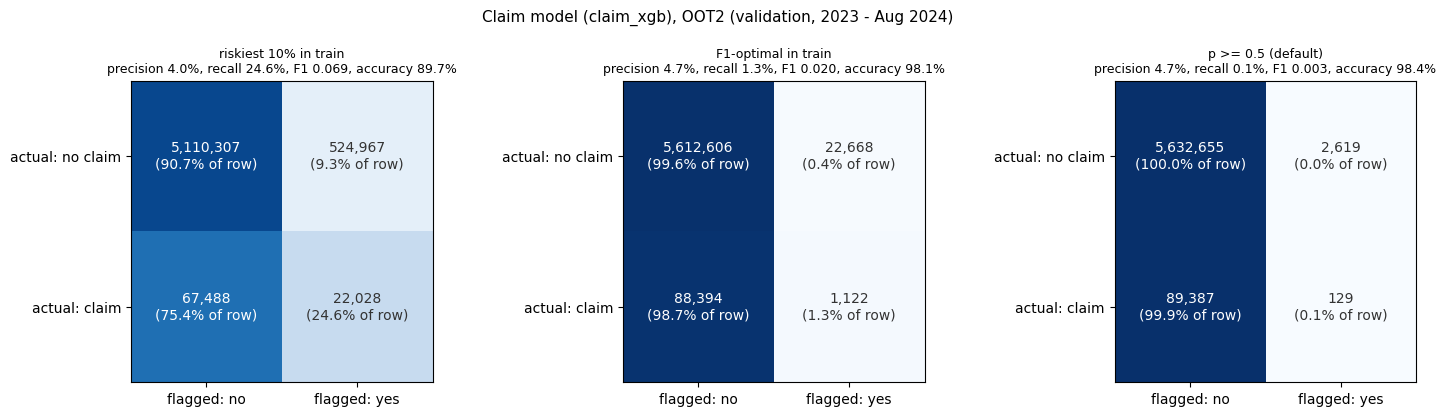

,model,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,fpr,lift
0,segment rate,riskiest 5% in train,0.0297,8.6%,"17,496","474,247","72,020","5,161,027",0.905,3.56%,19.5%,0.060,0.084,2.28
1,segment rate,riskiest 10% in train,0.0140,9.9%,"19,982","547,160","69,534","5,088,114",0.892,3.52%,22.3%,0.061,0.097,2.25
2,segment rate,riskiest 20% in train,0.0140,9.9%,"19,982","547,160","69,534","5,088,114",0.892,3.52%,22.3%,0.061,0.097,2.25
3,segment rate,F1-optimal in train,0.0297,8.6%,"17,496","474,247","72,020","5,161,027",0.905,3.56%,19.5%,0.060,0.084,2.28
4,segment rate,p >= 0.5 (default),0.5000,0.0%,0,0,"89,516","5,635,274",0.984,0.00%,0.0%,0.000,0.000,0.00
5,claim_baseline_logreg,riskiest 5% in train,0.0335,6.1%,"14,079","333,133","75,437","5,302,141",0.929,4.05%,15.7%,0.064,0.059,2.59
6,claim_baseline_logreg,riskiest 10% in train,0.0249,14.8%,"25,299","819,867","64,217","4,815,407",0.846,2.99%,28.3%,0.054,0.145,1.91
7,claim_baseline_logreg,riskiest 20% in train,0.0179,33.9%,"47,087","1,891,522","42,429","3,743,752",0.662,2.43%,52.6%,0.046,0.336,1.55
8,claim_baseline_logreg,F1-optimal in train,0.0334,6.1%,"14,177","336,964","75,339","5,298,310",0.928,4.04%,15.8%,0.064,0.060,2.58
9,claim_baseline_logreg,p >= 0.5 (default),0.5000,0.0%,0,0,"89,516","5,635,274",0.984,0.00%,0.0%,0.000,0.000,0.00


In [9]:
# Step 3.3 Claim: confusion matrices of every model at every rule
cm_claim = ev.classification_table(pred["claim"], "claim", COLS["claim"], RULES["claim"])
primary_rows = cm_claim[cm_claim["model"] == PRIMARY["claim"]].set_index("rule")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, rule in zip(axes, [main_rule, "F1-optimal in train", "p >= 0.5 (default)"]):
    ev.plot_confusion(ax, primary_rows.loc[rule].to_dict() | {"rule": rule}, "claim")
fig.suptitle(f"Claim model ({PRIMARY['claim']}), {EVAL_NAME}", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_confusion.png", dpi=150)
plt.show()
cm_claim.style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}",
                        "TN": "{:,}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}", "f1": "{:.3f}",
                        "fpr": "{:.3f}", "lift": "{:.2f}"})

#### 3.4 ROC curve
Every cut-off gives one confusion matrix; the ROC curve shows them all: the true positive rate (recall) against the false positive rate, $\text{FPR} = FP/(FP+TN)$, as the cut-off moves from 1 down to 0. The **AUC** is the probability that a random claim gets a higher score than a random policy-year without one (0.5 = chance, 1 = perfect). The dots mark the primary model's rules from Step 2.2.

ROC-AUC judges the **ranking** only: a model can rank well and still expect twice too many claims. 08b checks the probabilities themselves.

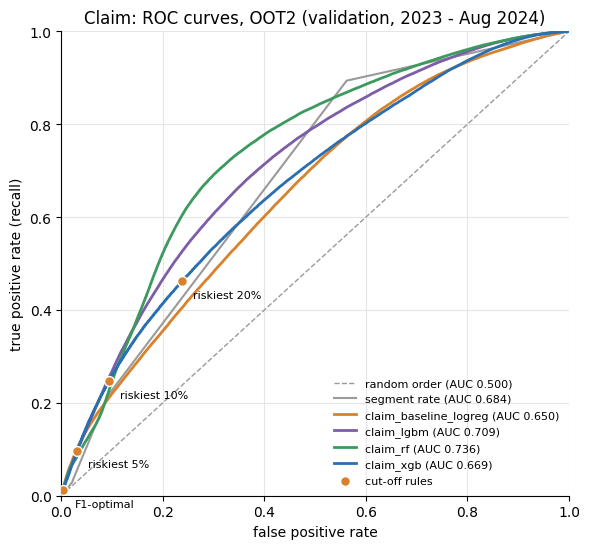

In [10]:
# Step 3.4 Claim: ROC curves of every model, with the primary model's rules marked
fig, ax = plt.subplots(figsize=(6, 5.6))
ev.plot_roc(ax, pred["claim"], COLS["claim"], cm_claim[cm_claim["model"] == PRIMARY["claim"]],
            f"Claim: ROC curves, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_roc.png", dpi=150)
plt.show()

#### 3.5 Train vs test vs validation
The same measures on each split, for every model at the main rule and at the default 0.5:
- **train** (2014–2020, in-sample): every training row, the years the model learned from (the predictions of Step 2.2);
- **test** (OOT1, 2021–2022);
- **validation** (OOT2, 2023 – Aug 2024): shown only in the final run (`EVAL_SPLIT = "valid"`).

Results much better on train than on test or validation would mean the model **overfits** the training years; similar results mean it generalizes to later years.

**Accuracy needs a reference.** Next to it we show the accuracy of always predicting *no claim*, $1 - \bar y$. With about 1% claims that is already about 99%, higher than any rule that flags a group, because every flagged policy-year without a claim costs accuracy. At the default 0.5 the model flags nobody, so its accuracy *equals* that reference. This is why we compare the splits on precision, recall and F1 as well, not on accuracy alone.

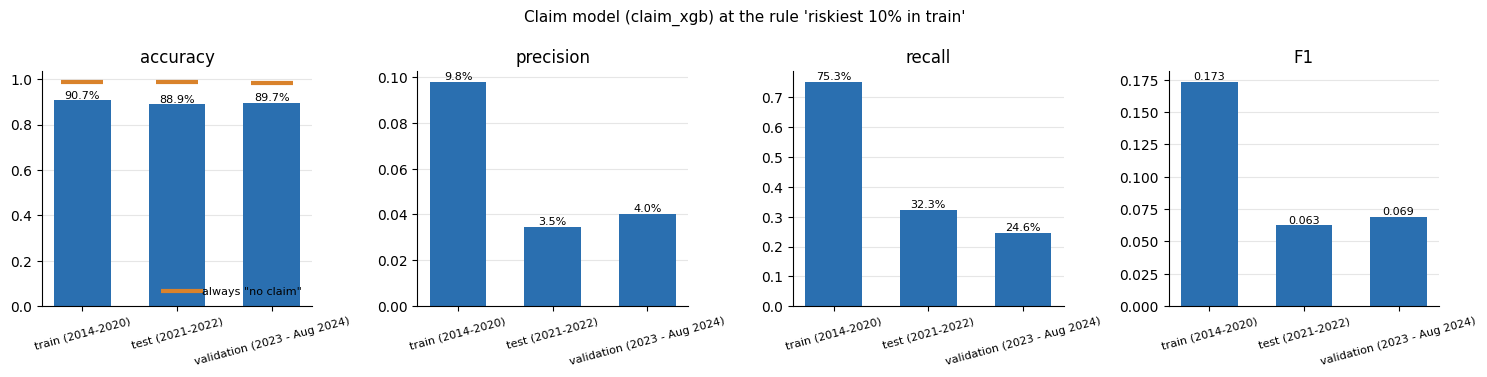

,split,model,rule,rows,actual_rate,accuracy_if_all_no,roc_auc,flagged_share,accuracy,precision,recall,f1
0,train (2014-2020),segment rate,riskiest 10% in train,"27,496,820",1.301%,98.699%,0.5986,53.5%,46.930%,1.66%,68.2%,0.032
1,train (2014-2020),segment rate,p >= 0.5 (default),"27,496,820",1.301%,98.699%,0.5986,0.0%,98.699%,0.00%,0.0%,0.000
2,train (2014-2020),claim_baseline_logreg,riskiest 10% in train,"27,496,820",1.301%,98.699%,0.6876,10.0%,89.378%,3.39%,26.1%,0.060
3,train (2014-2020),claim_baseline_logreg,p >= 0.5 (default),"27,496,820",1.301%,98.699%,0.6876,0.0%,98.699%,0.00%,0.0%,0.000
4,train (2014-2020),claim_lgbm,riskiest 10% in train,"27,496,820",1.301%,98.699%,0.9347,10.0%,90.792%,10.47%,80.4%,0.185
5,train (2014-2020),claim_lgbm,p >= 0.5 (default),"27,496,820",1.301%,98.699%,0.9347,0.5%,98.874%,68.51%,25.0%,0.366
6,train (2014-2020),claim_rf,riskiest 10% in train,"27,496,820",1.301%,98.699%,0.9113,10.0%,90.567%,9.34%,71.8%,0.165
7,train (2014-2020),claim_rf,p >= 0.5 (default),"27,496,820",1.301%,98.699%,0.9113,0.1%,98.737%,76.20%,4.3%,0.082
8,train (2014-2020),claim_xgb,riskiest 10% in train,"27,496,820",1.301%,98.699%,0.9151,10.0%,90.658%,9.80%,75.3%,0.173
9,train (2014-2020),claim_xgb,p >= 0.5 (default),"27,496,820",1.301%,98.699%,0.9151,0.3%,98.815%,70.76%,15.3%,0.251


In [11]:
# Step 3.5 Claim: accuracy and the other measures on the train, test and validation splits
if EVAL_SPLIT == "test":
    test_rows, valid_rows = pred["claim"], None                     # validation stays closed in the dry run
else:
    test_rows, valid_rows = ev.load_saved_test(PRED_DIR, registry["claim"]), pred["claim"]
splits_claim = ev.split_comparison("claim", {"train (2014-2020)": TRAIN_SCORED["claim"], "test (2021-2022)": test_rows,
                                                "validation (2023 - Aug 2024)": valid_rows}, COLS["claim"], RULES["claim"])

# Chart: the primary model at the main rule, split by split
t = splits_claim[(splits_claim["model"] == PRIMARY["claim"]) & (splits_claim["rule"] == main_rule)].dropna(subset=["accuracy"])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, ["accuracy", "precision", "recall", "f1"]):
    ax.bar(t["split"], t[m], color=ev.MODEL_COLORS[0], width=0.6)
    for x, val in zip(t["split"], t[m]):
        ax.text(x, val, f"{val:.3f}" if m == "f1" else f"{val:.1%}", ha="center", va="bottom", fontsize=8)
    if m == "accuracy":
        ax.scatter(t["split"], t["accuracy_if_all_no"], color="#d9822b", marker="_", s=900, linewidths=3, zorder=3,
                   label='always "no claim"')
        ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("F1" if m == "f1" else m)
    ax.tick_params(axis="x", labelsize=8, rotation=15)
    ev.style_axes(ax, grid="y")
fig.suptitle(f"Claim model ({PRIMARY['claim']}) at the rule '{main_rule}'", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_claim_by_split.png", dpi=150)
plt.show()
splits_claim.style.format({"rows": "{:,.0f}", "actual_rate": "{:.3%}", "accuracy_if_all_no": "{:.3%}", "roc_auc": "{:.4f}",
                            "flagged_share": "{:.1%}", "accuracy": "{:.3%}", "precision": "{:.2%}", "recall": "{:.1%}",
                            "f1": "{:.3f}"}, na_rep="-")

#### 3.6 Advanced models scored elsewhere: saved test results of 07a
A model can only be scored here if its file is in `data/processed/models/`. The 07 notebooks also save their **test results (2021–2022)** in `reports/`, so we read them for every advanced claim model that is not in the registry, and show them next to each other: the ROC-AUC by period, and the confusion-matrix measures at the main rule (riskiest 10%) and at the default 0.5.

Two cautions:
- these numbers come from the 07 notebook itself, with **its own cut-offs** (for example, the 07b random forest sets them on its out-of-bag training predictions, not on every training row as Step 2.2 does), so they are close to, but not exactly, what this notebook would give;
- they cover the **test years only**: there is no train or validation column for these models until their files are copied into `data/processed/models/`. From then on, the model is scored in every step above and this step skips it.

In [12]:
# Step 3.6 Claim: test results saved by the 07 notebooks for models that are not scored here
saved_07 = ev.saved_test_results("claim", REPORTS, skip=registry["claim"])
cm07_claim = pd.DataFrame()
if not saved_07:
    print("no saved test results of other claim models in reports/ yet")
else:
    aucs = []
    for name, res in saved_07.items():
        run = res["run"]
        print(f"{name}: saved {run.get('saved_at', '?')}; trained on {run.get('train_split', '?')}; "
              f"cut-offs: {run.get('cutoffs', 'see the 07 notebook')}")
        if res["auc"] is not None:
            aucs.append(res["auc"].rename_axis("model").reset_index().assign(source=name))
    if aucs:
        print("ROC-AUC by period (from the 07 notebooks)")
        display(pd.concat(aucs, ignore_index=True).set_index(["source", "model"]).style.format("{:.4f}"))
    cm07_claim = pd.concat([res["confusion"].assign(source=name) for name, res in saved_07.items()], ignore_index=True)
    shown = cm07_claim[cm07_claim["rule"].isin([main_rule, "p >= 0.5 (default)"])]

    # Chart: precision, recall and F1 at the main rule for every model in the saved tables
    t = shown[shown["rule"] == main_rule]
    labels = [f"{m}\n({s})" for m, s in zip(t["model"], t["source"])]
    x = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(max(8, 2.2 * len(t)), 4.4))
    for j, (m, color) in enumerate(zip(["precision", "recall", "f1"], ev.MODEL_COLORS)):
        ax.bar(x + (j - 1) * 0.26, t[m], width=0.26, color=color, label="F1" if m == "f1" else m)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set(title=f"Claim: test 2021-2022 at '{main_rule}'\n(saved by the 07 notebooks)", ylabel="share",
           ylim=(0, t[["precision", "recall", "f1"]].to_numpy().max() * 1.3))
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
    ev.style_axes(ax, grid="y")
    plt.tight_layout()
    plt.savefig(REPORTS / f"fig_{OUT}_claim_saved_07_results.png", dpi=150)
    plt.show()
    keep = [c for c in ["source", "model", "rule", "threshold", "flagged_share", "accuracy", "precision", "recall", "f1", "lift"]
            if c in shown]
    display(shown[keep].style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "accuracy": "{:.3f}",
                                      "precision": "{:.2%}", "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"}))

no saved test results of other claim models in reports/ yet


### Section 4. Lapse model

#### 4.1 Benchmark table
The same measures as Step 3.1, with the lapse main rule (flag the riskiest 20% of policy-years).

In [13]:
# Step 4.1 Lapse: ROC-AUC and the measures at the main rule, for every model, overall and per year
p = pred["lapse"]
scopes = [(EVAL_NAME, p), *[(str(y), g) for y, g in p.groupby("period_year")]]
bench_lapse, main_rule = ev.benchmark_classification("lapse", scopes, COLS["lapse"], RULES["lapse"])
print(f"main rule: {main_rule}")
bench_lapse.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "roc_auc": "{:.4f}",
                           "flagged_share": "{:.1%}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}",
                           "f1": "{:.3f}", "lift": "{:.2f}"}, na_rep="-")

main rule: riskiest 20% in train


,scope,model,rows,events,actual_rate,roc_auc,flagged_share,accuracy,precision,recall,f1,lift
0,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,621,274","578,846",10.297%,0.5000,-,-,-,-,-,-
1,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,621,274","578,846",10.297%,0.5736,15.5%,0.797,17.80%,26.9%,0.214,1.73
2,"OOT2 (validation, 2023 - Aug 2024)",lapse_baseline_logreg,"5,621,274","578,846",10.297%,0.6150,16.8%,0.789,17.96%,29.4%,0.223,1.74
3,"OOT2 (validation, 2023 - Aug 2024)",lapse_rf,"5,621,274","578,846",10.297%,0.6270,13.0%,0.819,19.87%,25.1%,0.222,1.93
4,"OOT2 (validation, 2023 - Aug 2024)",lapse_xgb,"5,621,274","578,846",10.297%,0.6187,12.9%,0.819,19.55%,24.5%,0.217,1.90
5,2023,base rate,"3,382,205","345,398",10.212%,0.5000,-,-,-,-,-,-
6,2023,segment rate,"3,382,205","345,398",10.212%,0.5777,18.9%,0.772,16.75%,31.0%,0.217,1.64
7,2023,lapse_baseline_logreg,"3,382,205","345,398",10.212%,0.6163,18.1%,0.780,17.46%,30.9%,0.223,1.71
8,2023,lapse_rf,"3,382,205","345,398",10.212%,0.6330,12.6%,0.823,20.13%,24.8%,0.222,1.97
9,2023,lapse_xgb,"3,382,205","345,398",10.212%,0.6212,13.8%,0.812,19.05%,25.8%,0.219,1.87


#### 4.2 Out-of-time 1 next to out-of-time 2 (or: dry-run check)
- **Final run (`"valid"`):** the same measures on OOT1, from the test predictions saved by 06b/07b, with the same cut-offs. A model whose results fall sharply from OOT1 to OOT2 was tuned too closely to 2021–2022.
- **Dry run (`"test"`):** the evaluation split *is* OOT1, so the ROC-AUC here must equal the one from the predictions saved by 06b. A difference means a model was loaded or prepared differently from how it was trained.

In [14]:
# Step 4.2 Lapse: OOT1 from the saved test predictions
saved = ev.load_saved_test(PRED_DIR, registry["lapse"])
if saved is None:
    print("no saved test predictions")
else:
    cols_saved = {n: c for n, c in COLS["lapse"].items() if c in saved}
    oot1, _ = ev.benchmark_classification("lapse", [("OOT1 (saved test predictions)", saved)], cols_saved, RULES["lapse"])
    if EVAL_SPLIT == "test":
        here = bench_lapse[bench_lapse["scope"] == EVAL_NAME].set_index("model")["roc_auc"]
        check = oot1.set_index("model")[["roc_auc"]].rename(columns={"roc_auc": "saved_by_06"}).join(here.rename("scored_here"))
        check["difference"] = check["scored_here"] - check["saved_by_06"]
        print("dry-run check: the two columns should match")
        display(check.style.format("{:.6f}"))
    else:
        both = pd.concat([oot1, bench_lapse[bench_lapse["scope"] == EVAL_NAME]], ignore_index=True)
        display(both.style.format({"rows": "{:,}", "events": "{:,}", "actual_rate": "{:.3%}", "roc_auc": "{:.4f}",
                                   "flagged_share": "{:.1%}", "accuracy": "{:.3f}", "precision": "{:.2%}",
                                   "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"}, na_rep="-"))

,scope,model,rows,events,actual_rate,roc_auc,flagged_share,accuracy,precision,recall,f1,lift
0,OOT1 (saved test predictions),base rate,"7,105,637","854,084",12.020%,0.5000,-,-,-,-,-,-
1,OOT1 (saved test predictions),segment rate,"7,105,637","854,084",12.020%,0.5938,14.8%,0.804,24.39%,30.1%,0.270,2.03
2,OOT1 (saved test predictions),lapse_baseline_logreg,"7,105,637","854,084",12.020%,0.6589,14.3%,0.806,24.23%,28.7%,0.263,2.02
3,OOT1 (saved test predictions),lapse_rf,"7,105,637","854,084",12.020%,0.6853,10.0%,0.834,27.03%,22.5%,0.246,2.25
4,OOT1 (saved test predictions),lapse_xgb,"7,105,637","854,084",12.020%,0.6767,10.6%,0.830,26.31%,23.2%,0.247,2.19
5,"OOT2 (validation, 2023 - Aug 2024)",base rate,"5,621,274","578,846",10.297%,0.5000,-,-,-,-,-,-
6,"OOT2 (validation, 2023 - Aug 2024)",segment rate,"5,621,274","578,846",10.297%,0.5736,15.5%,0.797,17.80%,26.9%,0.214,1.73
7,"OOT2 (validation, 2023 - Aug 2024)",lapse_baseline_logreg,"5,621,274","578,846",10.297%,0.6150,16.8%,0.789,17.96%,29.4%,0.223,1.74
8,"OOT2 (validation, 2023 - Aug 2024)",lapse_rf,"5,621,274","578,846",10.297%,0.6270,13.0%,0.819,19.87%,25.1%,0.222,1.93
9,"OOT2 (validation, 2023 - Aug 2024)",lapse_xgb,"5,621,274","578,846",10.297%,0.6187,12.9%,0.819,19.55%,24.5%,0.217,1.90


#### 4.3 Confusion matrices
Every model (except the base rate) at every rule of Step 2.2.

|  | Lapse ($y=1$) | No lapse ($y=0$) |
|---|---|---|
| **Flagged** ($p \ge c$) | TP | FP |
| **Not flagged** ($p < c$) | FN | TN |

**Why the default 0.5 is not enough:** With about 12% lapses, few policy-years reach a probability of 0.5, so the default flags very few, and accuracy is close to the 88% we would get by saying *stays* for everyone. **Accuracy is misleading for an imbalanced target**, so we read precision, recall and F1 instead.

**How to read it:** Lapse is much more common than a claim and the action is cheap (a renewal reminder, a call, an explanation of the premium change), so a retention team can contact a larger group and recall matters more: we use wider rules (10%, 20%, 30%). Precision is the share of contacted policyholders who would really leave; recall is the share of all lapses the campaign reaches.

The charts show the primary model at the main rule and at the default 0.5.

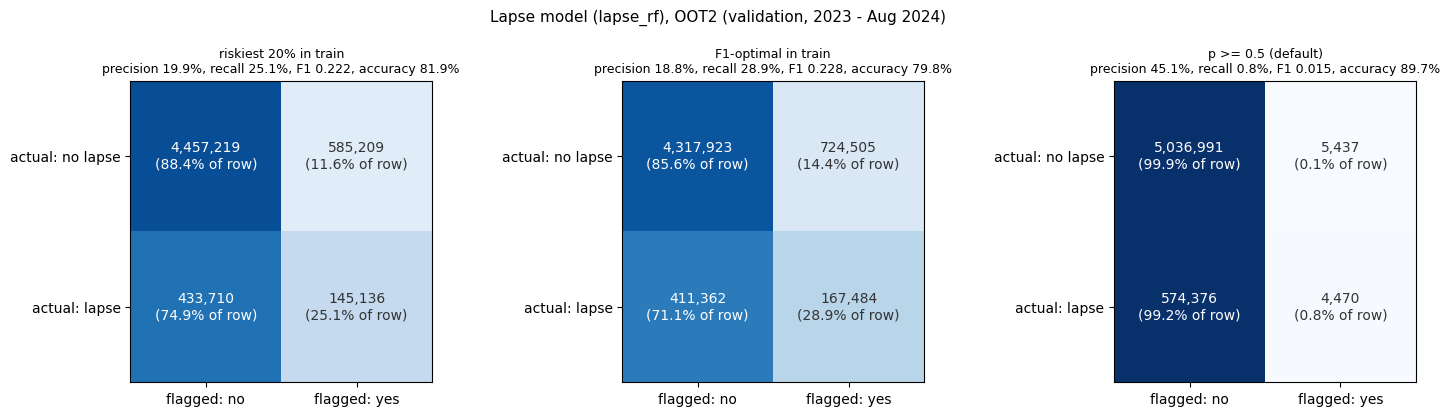

,model,rule,threshold,flagged_share,TP,FP,FN,TN,accuracy,precision,recall,f1,fpr,lift
0,segment rate,riskiest 10% in train,0.2351,0.0%,0,0,"578,846","5,042,428",0.897,0.00%,0.0%,0.000,0.000,0.00
1,segment rate,riskiest 20% in train,0.1598,15.5%,"155,494","717,900","423,352","4,324,528",0.797,17.80%,26.9%,0.214,0.142,1.73
2,segment rate,riskiest 30% in train,0.1189,15.7%,"157,071","724,809","421,775","4,317,619",0.796,17.81%,27.1%,0.215,0.144,1.73
3,segment rate,F1-optimal in train,0.1598,15.5%,"155,494","717,900","423,352","4,324,528",0.797,17.80%,26.9%,0.214,0.142,1.73
4,segment rate,p >= 0.5 (default),0.5000,0.0%,0,0,"578,846","5,042,428",0.897,0.00%,0.0%,0.000,0.000,0.00
5,lapse_baseline_logreg,riskiest 10% in train,0.2511,9.7%,"114,485","431,183","464,361","4,611,245",0.841,20.98%,19.8%,0.204,0.086,2.04
6,lapse_baseline_logreg,riskiest 20% in train,0.1935,16.8%,"170,012","776,553","408,834","4,265,875",0.789,17.96%,29.4%,0.223,0.154,1.74
7,lapse_baseline_logreg,riskiest 30% in train,0.1591,23.7%,"215,106","1,114,890","363,740","3,927,538",0.737,16.17%,37.2%,0.225,0.221,1.57
8,lapse_baseline_logreg,F1-optimal in train,0.1599,23.5%,"213,801","1,105,077","365,045","3,937,351",0.738,16.21%,36.9%,0.225,0.219,1.57
9,lapse_baseline_logreg,p >= 0.5 (default),0.5000,0.6%,"10,675","22,183","568,171","5,020,245",0.895,32.49%,1.8%,0.035,0.004,3.15


In [15]:
# Step 4.3 Lapse: confusion matrices of every model at every rule
cm_lapse = ev.classification_table(pred["lapse"], "lapse", COLS["lapse"], RULES["lapse"])
primary_rows = cm_lapse[cm_lapse["model"] == PRIMARY["lapse"]].set_index("rule")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, rule in zip(axes, [main_rule, "F1-optimal in train", "p >= 0.5 (default)"]):
    ev.plot_confusion(ax, primary_rows.loc[rule].to_dict() | {"rule": rule}, "lapse")
fig.suptitle(f"Lapse model ({PRIMARY['lapse']}), {EVAL_NAME}", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_confusion.png", dpi=150)
plt.show()
cm_lapse.style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "TP": "{:,}", "FP": "{:,}", "FN": "{:,}",
                        "TN": "{:,}", "accuracy": "{:.3f}", "precision": "{:.2%}", "recall": "{:.1%}", "f1": "{:.3f}",
                        "fpr": "{:.3f}", "lift": "{:.2f}"})

#### 4.4 ROC curve
As in Step 3.4, for the lapse models.

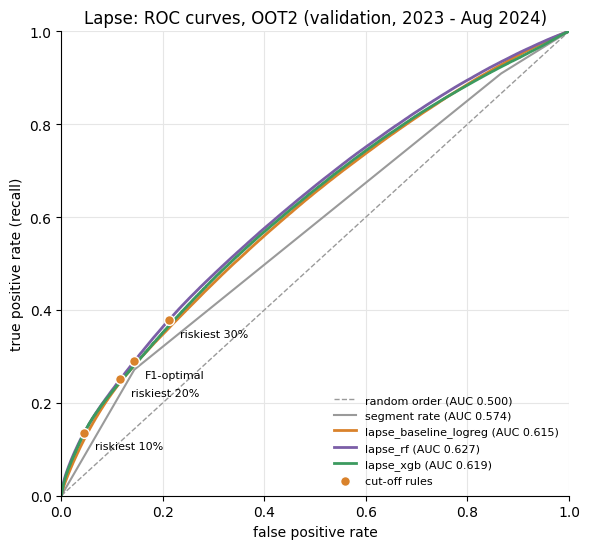

In [16]:
# Step 4.4 Lapse: ROC curves of every model, with the primary model's rules marked
fig, ax = plt.subplots(figsize=(6, 5.6))
ev.plot_roc(ax, pred["lapse"], COLS["lapse"], cm_lapse[cm_lapse["model"] == PRIMARY["lapse"]],
            f"Lapse: ROC curves, {EVAL_NAME}")
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_roc.png", dpi=150)
plt.show()

#### 4.5 Train vs test vs validation
As in Step 3.5. With about 12% lapses, always predicting *stays* already gives about 88% accuracy.

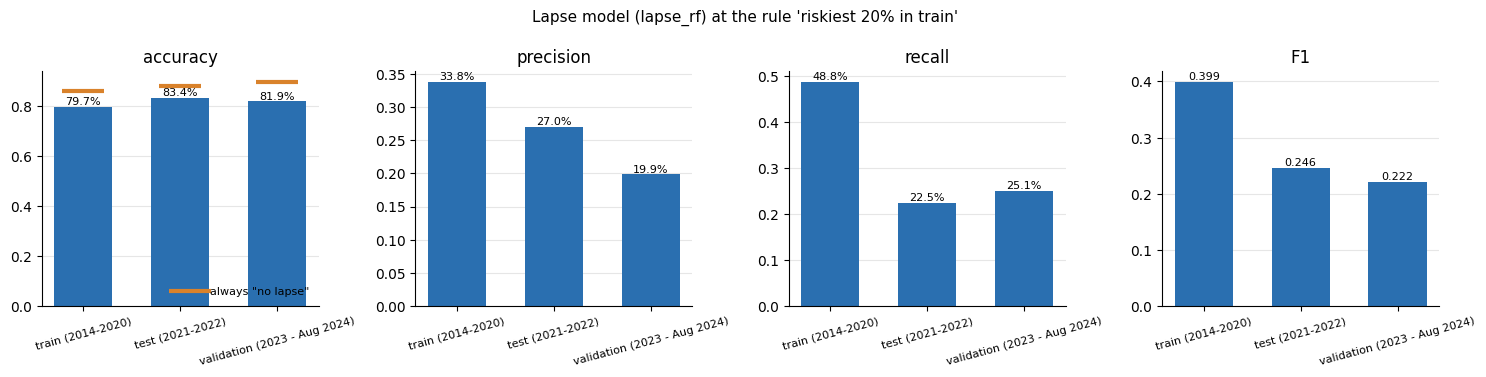

,split,model,rule,rows,actual_rate,accuracy_if_all_no,roc_auc,flagged_share,accuracy,precision,recall,f1
0,train (2014-2020),segment rate,riskiest 20% in train,"26,758,825",13.839%,86.161%,0.5804,20.7%,74.682%,22.23%,33.2%,0.266
1,train (2014-2020),segment rate,p >= 0.5 (default),"26,758,825",13.839%,86.161%,0.5804,0.0%,86.161%,0.00%,0.0%,0.000
2,train (2014-2020),lapse_baseline_logreg,riskiest 20% in train,"26,758,825",13.839%,86.161%,0.6926,20.0%,77.176%,27.54%,39.8%,0.326
3,train (2014-2020),lapse_baseline_logreg,p >= 0.5 (default),"26,758,825",13.839%,86.161%,0.6926,0.5%,86.186%,52.44%,1.9%,0.037
4,train (2014-2020),lapse_rf,riskiest 20% in train,"26,758,825",13.839%,86.161%,0.7697,20.0%,79.677%,33.79%,48.8%,0.399
5,train (2014-2020),lapse_rf,p >= 0.5 (default),"26,758,825",13.839%,86.161%,0.7697,1.2%,86.756%,75.14%,6.4%,0.118
6,train (2014-2020),lapse_xgb,riskiest 20% in train,"26,758,825",13.839%,86.161%,0.7541,20.0%,79.067%,32.27%,46.6%,0.381
7,train (2014-2020),lapse_xgb,p >= 0.5 (default),"26,758,825",13.839%,86.161%,0.7541,1.0%,86.632%,73.38%,5.3%,0.100
8,test (2021-2022),segment rate,riskiest 20% in train,"7,105,637",12.020%,87.980%,0.5938,14.8%,80.382%,24.39%,30.1%,0.270
9,test (2021-2022),segment rate,p >= 0.5 (default),"7,105,637",12.020%,87.980%,0.5938,0.0%,87.980%,0.00%,0.0%,0.000


In [17]:
# Step 4.5 Lapse: accuracy and the other measures on the train, test and validation splits
if EVAL_SPLIT == "test":
    test_rows, valid_rows = pred["lapse"], None                     # validation stays closed in the dry run
else:
    test_rows, valid_rows = ev.load_saved_test(PRED_DIR, registry["lapse"]), pred["lapse"]
splits_lapse = ev.split_comparison("lapse", {"train (2014-2020)": TRAIN_SCORED["lapse"], "test (2021-2022)": test_rows,
                                                "validation (2023 - Aug 2024)": valid_rows}, COLS["lapse"], RULES["lapse"])

# Chart: the primary model at the main rule, split by split
t = splits_lapse[(splits_lapse["model"] == PRIMARY["lapse"]) & (splits_lapse["rule"] == main_rule)].dropna(subset=["accuracy"])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, ["accuracy", "precision", "recall", "f1"]):
    ax.bar(t["split"], t[m], color=ev.MODEL_COLORS[0], width=0.6)
    for x, val in zip(t["split"], t[m]):
        ax.text(x, val, f"{val:.3f}" if m == "f1" else f"{val:.1%}", ha="center", va="bottom", fontsize=8)
    if m == "accuracy":
        ax.scatter(t["split"], t["accuracy_if_all_no"], color="#d9822b", marker="_", s=900, linewidths=3, zorder=3,
                   label='always "no lapse"')
        ax.legend(frameon=False, fontsize=8, loc="lower right")
    ax.set_title("F1" if m == "f1" else m)
    ax.tick_params(axis="x", labelsize=8, rotation=15)
    ev.style_axes(ax, grid="y")
fig.suptitle(f"Lapse model ({PRIMARY['lapse']}) at the rule '{main_rule}'", fontsize=11)
plt.tight_layout()
plt.savefig(REPORTS / f"fig_{OUT}_lapse_by_split.png", dpi=150)
plt.show()
splits_lapse.style.format({"rows": "{:,.0f}", "actual_rate": "{:.3%}", "accuracy_if_all_no": "{:.3%}", "roc_auc": "{:.4f}",
                            "flagged_share": "{:.1%}", "accuracy": "{:.3%}", "precision": "{:.2%}", "recall": "{:.1%}",
                            "f1": "{:.3f}"}, na_rep="-")

#### 4.6 Advanced models scored elsewhere: saved test results of 07b
A model can only be scored here if its file is in `data/processed/models/`. The 07 notebooks also save their **test results (2021–2022)** in `reports/`, so we read them for every advanced lapse model that is not in the registry, and show them next to each other: the ROC-AUC by period, and the confusion-matrix measures at the main rule (riskiest 20%) and at the default 0.5.

Two cautions:
- these numbers come from the 07 notebook itself, with **its own cut-offs** (for example, the 07b random forest sets them on its out-of-bag training predictions, not on every training row as Step 2.2 does), so they are close to, but not exactly, what this notebook would give;
- they cover the **test years only**: there is no train or validation column for these models until their files are copied into `data/processed/models/`. From then on, the model is scored in every step above and this step skips it.

In [18]:
# Step 4.6 Lapse: test results saved by the 07 notebooks for models that are not scored here
saved_07 = ev.saved_test_results("lapse", REPORTS, skip=registry["lapse"])
cm07_lapse = pd.DataFrame()
if not saved_07:
    print("no saved test results of other lapse models in reports/ yet")
else:
    aucs = []
    for name, res in saved_07.items():
        run = res["run"]
        print(f"{name}: saved {run.get('saved_at', '?')}; trained on {run.get('train_split', '?')}; "
              f"cut-offs: {run.get('cutoffs', 'see the 07 notebook')}")
        if res["auc"] is not None:
            aucs.append(res["auc"].rename_axis("model").reset_index().assign(source=name))
    if aucs:
        print("ROC-AUC by period (from the 07 notebooks)")
        display(pd.concat(aucs, ignore_index=True).set_index(["source", "model"]).style.format("{:.4f}"))
    cm07_lapse = pd.concat([res["confusion"].assign(source=name) for name, res in saved_07.items()], ignore_index=True)
    shown = cm07_lapse[cm07_lapse["rule"].isin([main_rule, "p >= 0.5 (default)"])]

    # Chart: precision, recall and F1 at the main rule for every model in the saved tables
    t = shown[shown["rule"] == main_rule]
    labels = [f"{m}\n({s})" for m, s in zip(t["model"], t["source"])]
    x = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(max(8, 2.2 * len(t)), 4.4))
    for j, (m, color) in enumerate(zip(["precision", "recall", "f1"], ev.MODEL_COLORS)):
        ax.bar(x + (j - 1) * 0.26, t[m], width=0.26, color=color, label="F1" if m == "f1" else m)
    ax.set_xticks(x, labels, fontsize=8)
    ax.set(title=f"Lapse: test 2021-2022 at '{main_rule}'\n(saved by the 07 notebooks)", ylabel="share",
           ylim=(0, t[["precision", "recall", "f1"]].to_numpy().max() * 1.3))
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
    ev.style_axes(ax, grid="y")
    plt.tight_layout()
    plt.savefig(REPORTS / f"fig_{OUT}_lapse_saved_07_results.png", dpi=150)
    plt.show()
    keep = [c for c in ["source", "model", "rule", "threshold", "flagged_share", "accuracy", "precision", "recall", "f1", "lift"]
            if c in shown]
    display(shown[keep].style.format({"threshold": "{:.4f}", "flagged_share": "{:.1%}", "accuracy": "{:.3f}",
                                      "precision": "{:.2%}", "recall": "{:.1%}", "f1": "{:.3f}", "lift": "{:.2f}"}))

no saved test results of other lapse models in reports/ yet


### Section 5. Conclusions and save

#### 5.1 Our findings (final run: validation, OOT2 = policy-years 2023 – Aug 2024)

All cut-offs were set on 2014–2020 and kept unchanged. Test (OOT1, 2021–2022) results come from the predictions saved by 06a/06b/07a/07b.

> **Correction to the saved segment-rule rows.** In this run, the segment rule's confusion rows (Steps 3.1, 3.3, 3.5, 4.1, 4.3, 4.5) were understated by a rounding bug: the cut-offs come from float32 training scores, and every policy in a segment has the *same* score, so a whole segment could fall just below its own cut-off (for example, lapse "riskiest 10%" flagged 0%). We fixed `ev.confusion_row` (it now compares in float32); the **model rows did not change** (largest difference 1e-7). The segment-rule numbers below are the corrected ones; re-running this notebook updates the tables and charts.

**Claim model** (claim rate: train 1.30%, test 1.15%, validation 1.56%; 2023: 0.97%, 2024: 2.46%)

1. **Ranking (ROC-AUC, Steps 3.1, 3.4):** in 2023–24 the random forest (**0.736**) and LightGBM (0.709) rank best, ahead of the segment rule (0.685), XGBoost (0.669) and the logistic regression (0.650). On the test years the order was different (logistic regression 0.657 ahead of the trees, 0.61–0.64), so **no claim model is best in both out-of-time periods**.
2. **Same list size:** flagging exactly the riskiest **10%** of 2023–24 policy-years catches 26.2% of claims with LightGBM, 25.4% with XGBoost, 23.9% with the random forest, 21.7% with the logistic regression and 22.8% with the segment rule. The trees beat the logistic regression in both periods, but their gain over the segment rule shrank from 6–11 points (test) to **1–3 points** (validation). At 20%, the random forest catches the most claims (51%, against 35% for the logistic regression).
3. **Confusion matrices at the main rule (riskiest 10% in train, Step 3.3):** XGBoost (primary) flags 9.6% of policy-years, catches 24.6% of claims, precision 4.0%, lift 2.58; the random forest flags 16.4%, recall 40.9%, precision 3.9%, lift 2.50; the logistic regression flags 14.8%, recall 28.3%, precision 3.0%, lift 1.91; the segment rule flags 56.7% (one large segment), recall 89.4%, lift 1.58. With claims this rare, a good list is still mostly policies without a claim: the value is the **2.5× concentration**. At **p ≥ 0.5** the models flag (almost) nobody: accuracy 98.4%, the same as predicting "no claim" for everyone, with recall near 0%. We recommend the riskiest 10% (or 5% for a tighter underwriting review), never 0.5.
4. **Train vs test vs validation (Step 3.5):** the tree models score **0.91–0.94 AUC on the training years** but 0.61–0.74 out of time: they fit the training years far more closely than they generalize (their training scores are partly in-sample). The logistic regression is steadier (0.69 → 0.66 → 0.65). Accuracy on every split is at or below "always no claim" (98.7%, 98.9%, 98.4%), which confirms accuracy can't judge these models.
5. **Primary model:** 08a chose **XGBoost** before opening the holdout (best test recall at 10%). Validation does not confirm it as the best (the random forest leads on AUC and at 20%, LightGBM at 10%); we keep it to avoid choosing a model on the holdout, and report the trees as close and unstable in their order.

**Lapse model** (lapse rate: train 13.8%, test 12.0%, validation 10.3%)

6. **Ranking (Steps 4.1, 4.4):** the **random forest ranks best in every period** (AUC 0.770 train, 0.685 test, **0.627** validation), ahead of XGBoost (0.754, 0.677, 0.619), the logistic regression (0.693, 0.659, 0.615) and the segment rule (0.580, 0.594, 0.574). Every model **loses ranking power over time**, while the lapse rate falls.
7. **Same list size:** flagging the riskiest **20%** of 2023–24 policy-years catches 34.3% of lapses with the random forest, 33.2% with XGBoost, 33.1% with the logistic regression and 31.0% with the segment rule (test: 38.9%, 38.0%, 37.2%, 35.6%). The models' gain over the simple rule is real but modest: **2–3 points of recall**.
8. **Confusion matrices at the main rule (riskiest 20% in train, Step 4.3):** the random forest flags 13.0% of policy-years, catches 25.1% of lapses, precision 19.9%, lift **1.93**; XGBoost 12.9%, 24.5%, 19.6%, 1.90; the logistic regression 16.8%, 29.4%, 18.0%, 1.74; the segment rule 15.7%, 27.1%, 17.8%, 1.73. Every model flags **fewer than 20%**, because lapse risk (and the scores) fell after 2020: a cut-off fixed on 2014–2020 gives a shrinking list. In use, the retention team should flag **the riskiest 20% of each year's renewals**. At p ≥ 0.5 the random forest flags 0.2% and catches 0.8% of lapses (accuracy 89.7%, the same as "nobody lapses").
9. **Train vs test vs validation (Step 4.5):** the gap between training and out-of-time AUC is moderate for the logistic regression (0.69 → 0.62) and larger for the trees (0.77 → 0.63 for the random forest), but the trees stay ahead out of time.

**Overall (classification view)**

10. Both targets are **predictable but weakly**: AUC 0.62–0.74 and lift 1.7–2.6× at realistic list sizes. The models are tools to **prioritize** a list, not to predict individual outcomes.
11. **Lapse:** the random forest is the model to use. **Claims:** the tree models rank better than the logistic regression on the latest years, but their order changes from period to period and they add little over a simple zone × earlier-claim rule; the probability checks in 08b explain why (claims follow storms the models can't see in advance).

#### 5.2 Save the results
The tables go to `reports/` with the prefix `eval_test_` (dry run) or `eval_valid_` (final run), next to the charts saved above. The predictions were saved in Step 2.1.

In [19]:
# Step 5.2 Save the benchmark tables, the confusion matrices and the cut-offs
for kind, bench, cm, by_split in [("claim", bench_claim, cm_claim, splits_claim), ("lapse", bench_lapse, cm_lapse, splits_lapse)]:
    bench.to_csv(REPORTS / f"{OUT}_{kind}_benchmark_classification.csv", index=False)
    by_split.to_csv(REPORTS / f"{OUT}_{kind}_by_split.csv", index=False)
    if len(globals().get(f"cm07_{kind}", [])):
        globals()[f"cm07_{kind}"].to_csv(REPORTS / f"{OUT}_{kind}_saved_07_confusion.csv", index=False)
    cm.to_csv(REPORTS / f"{OUT}_{kind}_confusion.csv", index=False)
pd.DataFrame([{"target": k, "model": m, "rule": r, "cut_off": c} for k in RULES for m in RULES[k] for r, c in RULES[k][m].items()]
             ).to_csv(REPORTS / f"{OUT}_cutoffs.csv", index=False)
print(f"saved {OUT}_* tables and charts to {REPORTS}")

saved eval_valid_* tables and charts to /Users/sebastiancarino/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk/reports
